# 0. Quick Start: Configuration

Run this cell first after every kernel restart. It restores only lightweight,
project-wide constants and paths. It does not load images, restore the model,
run inference, or train anything.


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

# Locate the project without hard-coding a computer-specific drive or folder.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    path
    for path in [CURRENT_DIR, *CURRENT_DIR.parents]
    if (path / "notebooks").exists()
    and (path / "src").exists()
)

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
INTERIM_DATA_DIR = DATA_DIR / "interim"
CACHE_DATA_DIR = DATA_DIR / "cache_1000"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures_v2"
MODELS_DIR = OUTPUTS_DIR / "models"
RESULTS_DIR = OUTPUTS_DIR / "results_v2"

METADATA_PATH = INTERIM_DATA_DIR / "final_clean_metadata.csv"
BEST_MODEL_PATH = MODELS_DIR / "best_resnet18_high_res_v2.pth"

# The order is fixed because it matches the six model output positions.
CLASS_NAMES = [
    "BIRD",
    "CAT",
    "EMPTY",
    "HEDGEHOG",
    "POSSUM",
    "RODENT",
]
CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}
NUM_CLASSES = len(CLASS_NAMES)
ALERT_CLASSES = {
    "CAT",
    "HEDGEHOG",
    "POSSUM",
    "RODENT",
}

IMAGE_SIZE = 1000
INFERENCE_BATCH_SIZE = 2
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Device:", device)
print("Quick-start configuration complete.")


Project: E:\Code\ai-predator-early-warning
Device: cuda
Quick-start configuration complete.


# 1. Setup and Data Loading


Import the libraries and define the main project paths.

## 1.1 Load Metadata

Load the cleaned dataset metadata created in the previous notebook.

In [5]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (17963, 9)


,sequence,image_sequence,file,label,site,date,camera,project_class,split
0,21050,image1,130616115348005as131.jpg,BIRD,005a,6/13/2016 11:53,s13,BIRD,train
1,77378,image2,1106150852100835S082.jpg,BIRD,835,6/11/2015 8:52,S08,BIRD,train
2,41636,image3,210916072714043as433.jpg,BIRD,043a,9/21/2016 7:27,s43,BIRD,train
3,58458,image2,240916111910017as082.jpg,BIRD,017a,9/24/2016 11:19,s08,BIRD,train
4,36044,image2,161016171542019b9705.jpg,BIRD,019b,10/16/2016 17:15,970,BIRD,train


In [25]:
pd.crosstab(
    df["project_class"],
    df["split"]
)

split,test,train,val
project_class,,,
BIRD,449,2090,448
CAT,450,2097,450
EMPTY,446,2085,448
HEDGEHOG,450,2100,450
POSSUM,450,2100,450
RODENT,450,2100,450


#### Class Balance After Cleaning

The final dataset has small differences in class size because low-quality images were removed.

The class distribution is still relatively balanced, so no additional resampling is applied.

## 1.2 Define Classes and Device

Define the six classes used in the classification model.

In [ ]:
# CLASS_NAMES, CLASS_TO_INDEX and NUM_CLASSES are already defined in Section 0, so only display the class-to-index mapping here
CLASS_TO_INDEX

{'BIRD': 0, 'CAT': 1, 'EMPTY': 2, 'HEDGEHOG': 3, 'POSSUM': 4, 'RODENT': 5}


Use a GPU if one is available. Otherwise, use the CPU.

In [27]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: not available; CPU will be used.")

Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


# 2. Data Pipeline

## 2.1 Image Transforms


Define image transformations for training, validation, and testing.

Training images use light augmentation. Validation and test images only use resizing and normalization.

In [ ]:
IMAGE_SIZE = 1000

train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    # Data augmentation: every time you read the exact same image, it comes out slightly different, so the model won't just memorize stuff by rote that easily.
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    # PIL image (H, W, 3, values 0-255) -> tensor (3, H, W, values 0-1)
    transforms.ToTensor(),
    # Standardise each RGB channel with the ImageNet mean and std.
    # Required because the pretrained ResNet18 was trained on inputs normalised this way; validation, test and inference must match.
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
# Evaluation: no random augmentation, so results are repeatable
eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 2.2 Dataset Class


Create a custom PyTorch dataset to load images and class labels from the metadata.

In [29]:
class CameraTrapDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.image_dir
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path).convert("RGB")

        label = CLASS_TO_INDEX[row["project_class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

## 2.3 Create Split DataFrames

Split the metadata into training, validation, and test sets.

In [ ]:
# The site-based split was already done in notebook 01
# here we only separate the rows into three tables.
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 12572
Validation: 2696
Test: 2695


## 2.4 Create Image Cache

In [11]:
CACHE_DATA_DIR = PROJECT_ROOT / "data" / "cache_1000"

CACHE_DATA_DIR.mkdir( 
    parents=True,
    exist_ok=True
)

cache_resize = transforms.Resize(1000)

In [6]:
from tqdm.auto import tqdm

new_cache_count = 0

for _, row in tqdm(
    df.iterrows(),
    total=len(df)
):
    source_path = (
        PROCESSED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    target_path = (
        CACHE_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    # Skip images already cached
    if target_path.exists():
        continue

    target_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    with Image.open(source_path) as image:
        image = image.convert("RGB")

        # Resize the shorter side to 1000 pixels
        image = cache_resize(image)

        image.save(
            target_path,
            quality=90
        )

    new_cache_count += 1

missing_cache_files = []
for _, row in df.iterrows():
    cache_path = (
        CACHE_DATA_DIR / row["split"]
        / row["project_class"] / row["file"]
    )
    if not cache_path.exists():
        missing_cache_files.append(str(cache_path))

if missing_cache_files:
    raise FileNotFoundError(
        f"Missing cached images: {len(missing_cache_files)}"
    )

print("New cached images:", new_cache_count)
print("V2 cached images ready:", len(df))

  0%|          | 0/17963 [00:00<?, ?it/s]

New cached images: 0
V2 cached images ready: 17963


## 2.5 Use Cached Images

In [ ]:
# Wrap each split in a Dataset. 
# Images are not loaded here; they are read one by one when the DataLoader requests them
# Only the training set uses random augmentation

train_dataset = CameraTrapDataset(
    train_df,
    CACHE_DATA_DIR,
    transform=train_transform
)

val_dataset = CameraTrapDataset(
    val_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

test_dataset = CameraTrapDataset(
    test_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

## 2.6 Create Safe DataLoaders

In [ ]:
BATCH_SIZE = 2 # Batch size is 2 because 1000-px images use a lot of GPU memory
train_generator = torch.Generator().manual_seed(SEED) # Seeded generator: the training shuffle order is reproducible.

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

## 2.7 Check Cached Image

In [17]:
row = train_df.iloc[0]

test_path = (
    CACHE_DATA_DIR
    / row["split"]
    / row["project_class"]
    / row["file"]
)

print("Exists:", test_path.exists())

with Image.open(test_path) as image:
    print("Image size:", image.size)

Exists: True
Image size: (1333, 1000)


## 2.8 Test Loading Speed

In [18]:
import time

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i == 9:
        break

elapsed = time.time() - start

print(f"10 batches: {elapsed:.1f} seconds")

10 batches: 2.5 seconds


# 3. Baseline CNN

Create a simple CNN as a baseline model.

The baseline gives a simple reference before using a stronger pretrained model.

## 3.1 Model


In [31]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convert different image sizes to a fixed feature size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [32]:
baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = baseline_model(
    images.to(device)
)

print("Output:", outputs.shape)

Input: torch.Size([2, 3, 1000, 1333])
Output: torch.Size([2, 6])


In [33]:
NUM_CLASSES = len(CLASS_NAMES)

baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

baseline_model

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)

## 3.2 Loss and Optimizer

Use cross-entropy loss for multi-class classification. Cross-Entropy Loss measures how far the model's prediction deviates from the correct answer.

Use Adam(Adaptive Moment Estimation) to update the model weights. Adam is an optimizer that updates the model weights using the gradients of the loss. It adapts the step size for each weight, which usually makes training faster and more stable than plain gradient descent.

In [34]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

## 3.3 Training and Validation Functions

Create functions for model training and validation.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train the model for one full pass over the training set.

    Returns the average loss and accuracy of this epoch.
    """
    model.train()

    total_loss = 0 # sum of (loss x batch size), to get a per-image average later
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear the gradients left over from the previous batch
        optimizer.zero_grad()
        # Forward pass: predict, then measure how wrong the prediction is
        outputs = model(images)
        loss = criterion(outputs, labels)
        # Backward pass: compute the gradient of the loss for every weight
        loss.backward()
        # Update the weights using those gradients
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        # Predicted class = the one with the highest score
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0
    
    # No gradients needed: saves memory and speeds things up
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 3.4 Train the Model

Train the baseline CNN for five epochs and record the training and validation results.

In [36]:
import time

NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate_model(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

baseline_history_df = pd.DataFrame(history)
baseline_history_df.insert(
    0, "epoch", range(1, len(baseline_history_df) + 1)
)
BASELINE_HISTORY_PATH = (
    RESULTS_DIR / "baseline_training_history_v2.csv"
)
BASELINE_MODEL_PATH = MODELS_DIR / "baseline_cnn_v2.pth"
baseline_history_df.to_csv(BASELINE_HISTORY_PATH, index=False)
torch.save(baseline_model.state_dict(), BASELINE_MODEL_PATH)
print("Saved baseline history:", BASELINE_HISTORY_PATH)
print("Saved baseline model:", BASELINE_MODEL_PATH)

Epoch 1/5 | Train Loss: 1.5232 | Train Acc: 0.3082 | Val Loss: 1.4584 | Val Acc: 0.3238 | Time: 15.9 min
Epoch 2/5 | Train Loss: 1.4183 | Train Acc: 0.3846 | Val Loss: 1.4924 | Val Acc: 0.3405 | Time: 13.8 min
Epoch 3/5 | Train Loss: 1.3508 | Train Acc: 0.4228 | Val Loss: 1.5017 | Val Acc: 0.3238 | Time: 14.7 min
Epoch 4/5 | Train Loss: 1.3035 | Train Acc: 0.4520 | Val Loss: 1.4477 | Val Acc: 0.4091 | Time: 14.2 min
Epoch 5/5 | Train Loss: 1.2691 | Train Acc: 0.4717 | Val Loss: 1.5542 | Val Acc: 0.3201 | Time: 15.0 min
Saved baseline history: e:\Code\ai-predator-early-warning\outputs\results_v2\baseline_training_history_v2.csv
Saved baseline model: e:\Code\ai-predator-early-warning\outputs\models\baseline_cnn_v2.pth


## 3.5 Baseline Result

The high-resolution baseline CNN reached its best validation accuracy of **40.91% at epoch 4**.

Training accuracy continued to increase after epoch 4, while validation accuracy dropped in the final epoch and validation loss fluctuated upward. This suggests overfitting.

Despite the higher resolution input, the simple CNN still had limited classification performance

## 3.6 Plot Learning Curves

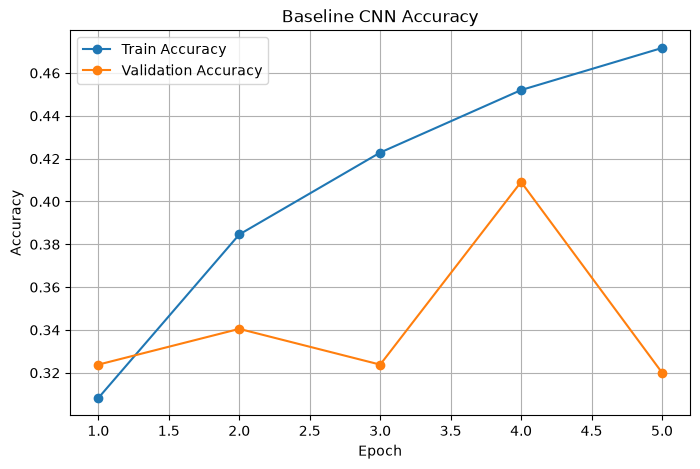

In [37]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()
plt.grid()

plt.show()

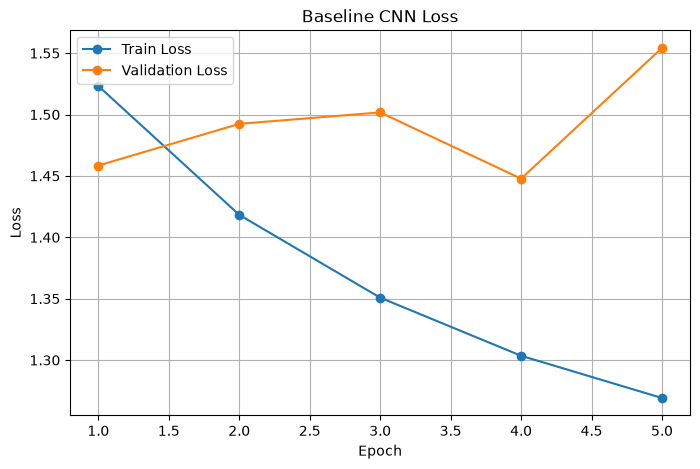

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()
plt.grid()

plt.show()

The baseline CNN overfitted.
Training accuracy kept going up in every epoch, but validation accuracy was highest at epoch 4 (40.91%) and then dropped sharply.
Validation loss went up and down, and it rose a lot in the last epoch. This shows that the model did not work well on new images it had not seen before.

# 4. ResNet18

Use a pretrained ResNet18 model and fine-tune it for the six wildlife classes.

## 4.1 Load Pretrained Model

In [ ]:
from torchvision.models import ResNet18_Weights
# DEFAULT = the best available pretrained weights (trained on ImageNet)
weights = ResNet18_Weights.DEFAULT

# Load ResNet18 with the pretrained weights (transfer learning)
resnet_model = models.resnet18(
    weights=weights
)
# The original last layer (fc) outputs 1000 ImageNet classes.
# Replace it with a new layer that outputs our 6 classes.  
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

resnet_model = resnet_model.to(device)

## 4.2 Loss and Optimizer

Use cross-entropy loss and Adam for fine-tuning.

In [ ]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    resnet_model.parameters(),
    lr=0.0001,#Small learning rate: we only fine-tune the pretrained weights.
    weight_decay=1e-4 #weight_decay adds a mild L2 penalty to reduce overfitting.
)

scaler = torch.amp.GradScaler("cuda")

## 4.3 Training Functions

Use mixed precision to reduce GPU memory use and speed up training.

In [ ]:
def train_one_epoch_amp(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        # GPU memory and speed up training
        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        # Scale the loss, backpropagate, then unscale gradients and update weights
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model_amp(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type="cuda"
            ):
                outputs = model(images)
                loss = criterion(
                    outputs,
                    labels
                )

            total_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 4.4 Train ResNet18

Train ResNet18 for ten epochs and save the best validation model.

In [42]:
import time

NUM_EPOCHS = 10

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

BEST_MODEL_PATH = (
    MODELS_DIR
    / "best_resnet18_high_res_v2.pth"
)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch_amp(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device,
        scaler
    )

    val_loss, val_accuracy = evaluate_model_amp(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(
        train_loss
    )

    resnet_history["train_accuracy"].append(
        train_accuracy
    )

    resnet_history["val_loss"].append(
        val_loss
    )

    resnet_history["val_accuracy"].append(
        val_accuracy
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

print(
    "\nBest Val Acc:",
    round(best_val_accuracy, 4)
)

print(
    "Saved model:",
    BEST_MODEL_PATH
)

RESNET_HISTORY_PATH = (
    RESULTS_DIR / "resnet18_training_history_v2.csv"
)
resnet_history_df = pd.DataFrame(resnet_history)
resnet_history_df.insert(
    0, "epoch", range(1, len(resnet_history_df) + 1)
)
resnet_history_df.to_csv(RESNET_HISTORY_PATH, index=False)
print("Saved training history:", RESNET_HISTORY_PATH)

Epoch 1/10 | Train Loss: 1.1922 | Train Acc: 0.5165 | Val Loss: 1.1976 | Val Acc: 0.5783 | Time: 22.7 min
Epoch 2/10 | Train Loss: 0.8374 | Train Acc: 0.6656 | Val Loss: 0.9538 | Val Acc: 0.6777 | Time: 29.6 min
Epoch 3/10 | Train Loss: 0.6913 | Train Acc: 0.7383 | Val Loss: 1.1522 | Val Acc: 0.5942 | Time: 19.6 min
Epoch 4/10 | Train Loss: 0.6015 | Train Acc: 0.7729 | Val Loss: 0.7791 | Val Acc: 0.7044 | Time: 20.3 min
Epoch 5/10 | Train Loss: 0.5515 | Train Acc: 0.7898 | Val Loss: 0.8422 | Val Acc: 0.7107 | Time: 19.0 min
Epoch 6/10 | Train Loss: 0.5173 | Train Acc: 0.8091 | Val Loss: 0.9287 | Val Acc: 0.6665 | Time: 18.5 min
Epoch 7/10 | Train Loss: 0.4909 | Train Acc: 0.8135 | Val Loss: 0.8765 | Val Acc: 0.6792 | Time: 19.4 min
Epoch 8/10 | Train Loss: 0.4645 | Train Acc: 0.8274 | Val Loss: 0.8403 | Val Acc: 0.7085 | Time: 18.6 min
Epoch 9/10 | Train Loss: 0.4483 | Train Acc: 0.8287 | Val Loss: 0.9479 | Val Acc: 0.6944 | Time: 18.4 min
Epoch 10/10 | Train Loss: 0.4329 | Train Acc: 

## 4.6 Load the Best Model and Resume Inference

Load the best ResNet18 checkpoint saved during training (highest validation
accuracy, epoch 5 in the reported run), together with the validation/test
metadata and DataLoaders.

This also lets you restore everything after a kernel restart without
retraining. The cell only sets up inference: no optimizer is created and no
weights are updated.

In [5]:
# Requires Section 0 (imports, paths, constants) to be run first.
import sys

import torch.nn.functional as F  # used by Grad-CAM (Section 7.2)
from PIL import Image            # used to open images (Section 7)

# Make src/ importable: the notebook runs inside notebooks/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.inference_setup import load_inference_session, run_inference

# Load the BEST checkpoint plus the validation/test data and DataLoaders
resume_state = load_inference_session(
    project_root=PROJECT_ROOT,
    batch_size=2,
    num_workers=0,
)

# Restore the variable names used by the remaining notebook cells.
globals().update(resume_state)

print("Inference session restored.")
print("Device:", device)
print("Checkpoint:", BEST_MODEL_PATH)
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Inference session restored.
Device: cuda
Checkpoint: E:\Code\ai-predator-early-warning\outputs\models\best_resnet18_high_res_v2.pth
Validation images: 2696
Test images: 2695


# 5. Validation-Only Alert Policy Selection

Select the alert-score method and threshold using validation data only. Configurations within 0.001 of the best validation F1 are treated as practically tied; among them, higher recall is preferred because missed alerts are more costly. The test set remains untouched until the policy is fixed.

## 5.1 Run or Load Validation Predictions

Run validation inference once for the V2 model, then reuse the saved CSV after a kernel restart.


In [8]:
if "RESULTS_DIR" not in globals():
    raise RuntimeError(
        "Run Section 0: Quick Start Configuration first."
    )

VAL_PREDICTIONS_PATH = (
    RESULTS_DIR / "validation_predictions.csv"
)

if VAL_PREDICTIONS_PATH.exists():
    val_predictions_df = pd.read_csv(VAL_PREDICTIONS_PATH)
    prediction_source = "saved CSV"
else:
    val_predictions_df = run_inference(
        resnet_model,
        val_loader,
        val_df,
        device,
        CLASS_NAMES,
        ALERT_CLASSES,
    )
    val_predictions_df.to_csv(
        VAL_PREDICTIONS_PATH,
        index=False,
    )
    prediction_source = "new V2 inference"

if len(val_predictions_df) != len(val_df):
    raise ValueError(
        "Saved validation predictions have an unexpected row count."
    )

print("Validation prediction source:", prediction_source)
print("Validation predictions:", len(val_predictions_df))
print("Path:", VAL_PREDICTIONS_PATH)

display(
    val_predictions_df[
        [
            "file",
            "true_class",
            "predicted_class",
            "true_alert",
            "sum_alert_score",
            "max_alert_score",
        ]
    ].head()
)


Validation prediction source: saved CSV
Validation predictions: 2696
Path: E:\Code\ai-predator-early-warning\outputs\results_v2\validation_predictions.csv


,file,true_class,predicted_class,true_alert,sum_alert_score,max_alert_score
0,130816131544023a6241.jpg,BIRD,EMPTY,0,0.14770,0.062740
1,051116181530011b3102.jpg,BIRD,BIRD,0,0.02483,0.024380
2,04121511491202201162.jpg,BIRD,BIRD,0,0.12317,0.078370
3,041116110014023a9232.jpg,BIRD,EMPTY,0,0.01987,0.009476
4,230816170024011bs103.jpg,BIRD,EMPTY,0,0.15500,0.116640


## 5.2 Compare Sum and Max Alert Scores

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Candidate thresholds: 0.10, 0.15, ..., 0.90 (rounded to avoid float noise)
# parameters:starting point, the ending point, and the step size
THRESHOLDS = np.round(
    np.arange(0.10, 0.91, 0.05),
    2,
)


# Two ways to turn the 4 alert-class probabilities into one alert score:
#   sum = total probability of the alert classes
#   max = probability of the single most likely alert class
SCORE_METHODS = {
    "sum": "sum_alert_score",
    "max": "max_alert_score",
}


def evaluate_alert_thresholds(predictions_df, thresholds):
    """Evaluate every (score method, threshold) pair as a binary
    alert / no-alert classifier. Returns one row per pair."""
    rows = []

    # 1 = a predator image (CAT/HEDGEHOG/POSSUM/RODENT), 0 = BIRD/EMPTY
    y_true = predictions_df["true_alert"].to_numpy()

    for method, score_column in SCORE_METHODS.items():
        scores = predictions_df[score_column].to_numpy()

        for threshold in thresholds:
            # Raise an alert when the score reaches the threshold. 
            y_pred = (scores >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1],
            ).ravel()

            rows.append(
                {
                    "method": method,
                    "score_column": score_column,
                    "threshold": float(threshold),
                    "accuracy": accuracy_score(y_true, y_pred),
                    # precision: of the alerts raised, how many were real.
                    "precision": precision_score(
                        y_true, y_pred, zero_division=0
                    ),
                     # recall: of the real predators, how many were caught.
                    "recall": recall_score(
                        y_true, y_pred, zero_division=0
                    ),
                    "f1": f1_score(
                        y_true, y_pred, zero_division=0
                    ),
                    # F2: like F1 but weights recall more (reported only,                # not used for selection).
                    "f2": fbeta_score(
                        y_true, y_pred, beta=2, zero_division=0
                    ),
                    "true_negatives": int(tn),
                    "false_alerts": int(fp),
                    "missed_alerts": int(fn),
                    "true_positives": int(tp),
                }
            )

    return pd.DataFrame(rows)

# Evaluate all methods and thresholds on VALIDATION data only (the test set stays untouched).
validation_threshold_df = evaluate_alert_thresholds(
    val_predictions_df,
    THRESHOLDS,
)

# Pre-declared early-warning selection rule:
# treat F1 values within 0.001 of the best as practically tied, then prefer
# higher recall, higher precision, and finally the lower threshold.
MAX_VALIDATION_F1 = validation_threshold_df["f1"].max()
F1_TOLERANCE = 0.001

# Keep only the near-best configurations.
near_best_validation_df = validation_threshold_df[
    validation_threshold_df["f1"]
    >= MAX_VALIDATION_F1 - F1_TOLERANCE
].copy()

ranked_validation_df = near_best_validation_df.sort_values(
    by=["recall", "precision", "f1", "threshold"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

# The top-ranked row defines the fixed alert policy.
selected_validation_row = ranked_validation_df.iloc[0]
SELECTED_SCORE_METHOD = str(selected_validation_row["method"])
SELECTED_SCORE_COLUMN = str(selected_validation_row["score_column"])
SELECTED_THRESHOLD = float(selected_validation_row["threshold"])

best_by_method_df = (
    ranked_validation_df
    .drop_duplicates(subset="method", keep="first")
    .sort_values("method")
    .reset_index(drop=True)
)

# Apply the chosen policy to the validation predictions.
val_predictions_df["selected_alert_score"] = (
    val_predictions_df[SELECTED_SCORE_COLUMN]
)
val_predictions_df["selected_threshold"] = SELECTED_THRESHOLD
val_predictions_df["predicted_alert"] = (
    val_predictions_df["selected_alert_score"] >= SELECTED_THRESHOLD
).astype(int)

selected_policy_df = pd.DataFrame(
    [
        {
            "selection_split": "validation",
            "selection_rule": (
                "within_0.001_of_best_f1_then_recall_then_precision_then_lower_threshold"
            ),
            "method": SELECTED_SCORE_METHOD,
            "score_column": SELECTED_SCORE_COLUMN,
            "threshold": SELECTED_THRESHOLD,
            "validation_accuracy": selected_validation_row["accuracy"],
            "validation_precision": selected_validation_row["precision"],
            "validation_recall": selected_validation_row["recall"],
            "validation_f1": selected_validation_row["f1"],
            "validation_f2": selected_validation_row["f2"],
            "validation_false_alerts": int(
                selected_validation_row["false_alerts"]
            ),
            "validation_missed_alerts": int(
                selected_validation_row["missed_alerts"]
            ),
        }
    ]
)
# Save results: full threshold table, selected policy, updated predictions.
validation_threshold_df.to_csv(
    RESULTS_DIR / "validation_threshold_comparison.csv",
    index=False,
)
selected_policy_df.to_csv(
    RESULTS_DIR / "selected_alert_policy.csv",
    index=False,
)
val_predictions_df.to_csv(
    VAL_PREDICTIONS_PATH,
    index=False,
)

display(
    best_by_method_df[
        [
            "method",
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "f2",
            "false_alerts",
            "missed_alerts",
        ]
    ].round(4)
)

print("BEST VALIDATION F1:", f"{MAX_VALIDATION_F1:.6f}")
print("F1 NEAR-TIE TOLERANCE:", F1_TOLERANCE)
print("FIXED METHOD:", SELECTED_SCORE_METHOD)
print("FIXED SCORE COLUMN:", SELECTED_SCORE_COLUMN)
print("FIXED THRESHOLD:", f"{SELECTED_THRESHOLD:.2f}")


,method,threshold,accuracy,precision,recall,f1,f2,false_alerts,missed_alerts
0,sum,0.7,0.9158,0.9267,0.9489,0.9377,0.9444,135,92


BEST VALIDATION F1: 0.937689
F1 NEAR-TIE TOLERANCE: 0.001
FIXED METHOD: sum
FIXED SCORE COLUMN: sum_alert_score
FIXED THRESHOLD: 0.70


## 5.3 Validation Threshold Trade-off

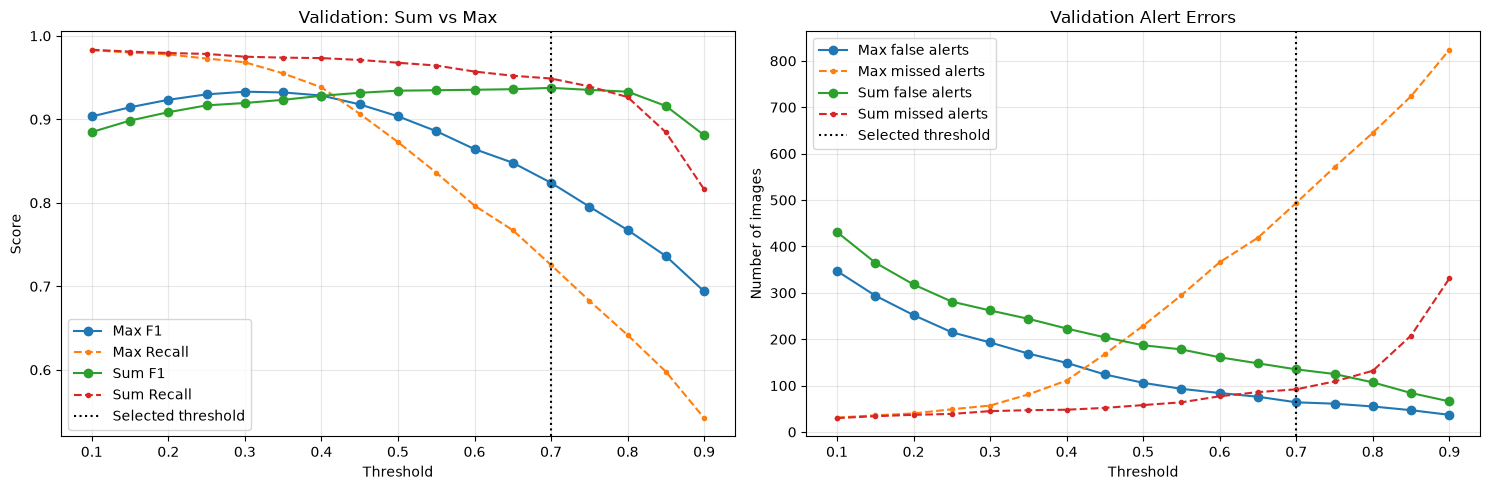

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for method, method_df in validation_threshold_df.groupby("method"):
    axes[0].plot(
        method_df["threshold"],
        method_df["f1"],
        marker="o",
        label=f"{method.title()} F1",
    )
    axes[0].plot(
        method_df["threshold"],
        method_df["recall"],
        marker=".",
        linestyle="--",
        label=f"{method.title()} Recall",
    )
    axes[1].plot(
        method_df["threshold"],
        method_df["false_alerts"],
        marker="o",
        label=f"{method.title()} false alerts",
    )
    axes[1].plot(
        method_df["threshold"],
        method_df["missed_alerts"],
        marker=".",
        linestyle="--",
        label=f"{method.title()} missed alerts",
    )

for axis in axes:
    axis.axvline(
        SELECTED_THRESHOLD,
        color="black",
        linestyle=":",
        label="Selected threshold",
    )
    axis.set_xlabel("Threshold")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_title("Validation: Sum vs Max")
axes[0].set_ylabel("Score")
axes[1].set_title("Validation Alert Errors")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "validation_sum_vs_max.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


### Validation Threshold Selection

The sum method achieved a higher and more stable F1 score than the max method.   
As the threshold increased, false alerts decreased, but missed alerts increased.  
Using the validation set only, the sum method with a threshold of 0.70 was selected.
It achieved a precision of 0.9267, recall of 0.9489, and F1 score of 0.9377. This policy was fixed before the final test evaluation to avoid test data leakage.

# 6. Fixed Final Test Evaluation

The alert method and threshold are now fixed. The test set is used once for
final performance estimation; no policy decision is changed after viewing the
following results.

## 6.1 Run or Load Final Test Predictions

After the validation policy is fixed, run test inference once for the V2 model, then reuse the saved CSV.


In [6]:
if "RESULTS_DIR" not in globals():
    raise RuntimeError(
        "Run Section 0: Quick Start Configuration first."
    )

TEST_PREDICTIONS_PATH = RESULTS_DIR / "test_predictions.csv"

if TEST_PREDICTIONS_PATH.exists():
    test_predictions_df = pd.read_csv(TEST_PREDICTIONS_PATH)
    prediction_source = "saved CSV"
else:
    test_predictions_df = run_inference(
        resnet_model,
        test_loader,
        test_df,
        device,
        CLASS_NAMES,
        ALERT_CLASSES,
    )
    test_predictions_df.to_csv(
        TEST_PREDICTIONS_PATH,
        index=False,
    )
    prediction_source = "new V2 inference"

if len(test_predictions_df) != len(test_df):
    raise ValueError(
        "Saved test predictions have an unexpected row count."
    )

print("Test prediction source:", prediction_source)
print("Test predictions:", len(test_predictions_df))
print("Path:", TEST_PREDICTIONS_PATH)


Test prediction source: saved CSV
Test predictions: 2695
Path: E:\Code\ai-predator-early-warning\outputs\results_v2\test_predictions.csv


## 6.2 Final Multiclass and Alert Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)

saved_class_index_table = (
    test_predictions_df[["true_class_index", "true_class"]]
    .drop_duplicates()
    .sort_values("true_class_index")
)
saved_class_names = saved_class_index_table["true_class"].tolist()

if saved_class_names != CLASS_NAMES:
    raise ValueError(
        "The saved prediction class order does not match CLASS_NAMES."
    )

if "SELECTED_THRESHOLD" not in globals():
    selected_policy_df = pd.read_csv(
        RESULTS_DIR / "selected_alert_policy.csv"
    )
    SELECTED_SCORE_METHOD = str(selected_policy_df.loc[0, "method"])
    SELECTED_SCORE_COLUMN = str(selected_policy_df.loc[0, "score_column"])
    SELECTED_THRESHOLD = float(selected_policy_df.loc[0, "threshold"])

# Apply the FIXED validation-selected policy to the test predictions:alert if the chosen score reaches the chosen threshold.
test_predictions_df["selected_score_method"] = SELECTED_SCORE_METHOD
test_predictions_df["selected_alert_score"] = (
    test_predictions_df[SELECTED_SCORE_COLUMN]
)
test_predictions_df["selected_threshold"] = SELECTED_THRESHOLD
test_predictions_df["predicted_alert"] = (
    test_predictions_df["selected_alert_score"] >= SELECTED_THRESHOLD
).astype(int)

# Arrays for the six-class task (class indices 0-5 and for the binary alert task (0 = no alert, 1 = alert).
y_test_class = test_predictions_df["true_class_index"].to_numpy()
y_test_class_pred = (
    test_predictions_df["predicted_class_index"].to_numpy()
)
y_test_alert = test_predictions_df["true_alert"].to_numpy()
y_test_alert_pred = test_predictions_df["predicted_alert"].to_numpy()

#Per-class precision / recall / F1 for the six-class model, as a table.
test_classification_report_df = pd.DataFrame(
    classification_report(
        y_test_class,
        y_test_class_pred,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        digits=4,
        zero_division=0,
    )
).T

tn, fp, fn, tp = confusion_matrix(
    y_test_alert,
    y_test_alert_pred,
    labels=[0, 1],
).ravel()

# Share of images whose exact class (1 of 6) was predicted correctly.
test_multiclass_accuracy = accuracy_score(
    y_test_class,
    y_test_class_pred,
)
# Binary alert metrics on the test set.
test_alert_metrics_df = pd.DataFrame(
    [
        {
            "method": SELECTED_SCORE_METHOD,
            "threshold": SELECTED_THRESHOLD,
            "accuracy": accuracy_score(y_test_alert, y_test_alert_pred),
            "precision": precision_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "recall": recall_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "f1": f1_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "f2": fbeta_score(
                y_test_alert,
                y_test_alert_pred,
                beta=2,
                zero_division=0,
            ),
            "true_negatives": int(tn),
            "false_alerts": int(fp),
            "missed_alerts": int(fn),
            "true_positives": int(tp),
        }
    ]
)
# One-row summary combining the six-class and alert results.
final_test_summary_df = pd.DataFrame(
    [
        {
            "multiclass_accuracy": test_multiclass_accuracy,
            "alert_method": SELECTED_SCORE_METHOD,
            "alert_threshold": SELECTED_THRESHOLD,
            "alert_accuracy": test_alert_metrics_df.loc[0, "accuracy"],
            "alert_precision": test_alert_metrics_df.loc[0, "precision"],
            "alert_recall": test_alert_metrics_df.loc[0, "recall"],
            "alert_f1": test_alert_metrics_df.loc[0, "f1"],
            "alert_f2": test_alert_metrics_df.loc[0, "f2"],
            "false_alerts": int(
                test_alert_metrics_df.loc[0, "false_alerts"]
            ),
            "missed_alerts": int(
                test_alert_metrics_df.loc[0, "missed_alerts"]
            ),
        }
    ]
)

test_predictions_df.to_csv(TEST_PREDICTIONS_PATH, index=False)
test_classification_report_df.to_csv(
    RESULTS_DIR / "final_test_classification_report.csv",
    index=True,
)
test_alert_metrics_df.to_csv(
    RESULTS_DIR / "final_test_alert_metrics.csv",
    index=False,
)
final_test_summary_df.to_csv(
    RESULTS_DIR / "final_test_summary.csv",
    index=False,
)

print("Fixed validation-selected policy")
print("Method:", SELECTED_SCORE_METHOD)
print("Threshold:", f"{SELECTED_THRESHOLD:.2f}")
print("Test multiclass accuracy:", f"{test_multiclass_accuracy:.4f}")
display(test_alert_metrics_df.round(4))
display(test_classification_report_df.round(4))


Fixed validation-selected policy
Method: sum
Threshold: 0.70
Test multiclass accuracy: 0.7039


,method,threshold,accuracy,precision,recall,f1,f2,true_negatives,false_alerts,missed_alerts,true_positives
0,sum,0.7,0.9262,0.947,0.9422,0.9446,0.9432,800,95,104,1696


,precision,recall,f1-score,support
BIRD,0.8640,0.4811,0.6180,449.0000
CAT,0.9135,0.5400,0.6788,450.0000
EMPTY,0.5571,0.7108,0.6246,446.0000
HEDGEHOG,0.8051,0.7067,0.7527,450.0000
POSSUM,0.5792,0.9511,0.7199,450.0000
RODENT,0.7878,0.8333,0.8099,450.0000
accuracy,0.7039,0.7039,0.7039,0.7039
macro avg,0.7511,0.7038,0.7007,2695.0000
weighted avg,0.7514,0.7039,0.7008,2695.0000


### Discover

On the test set, the fixed alert policy reached a precision of 0.947, a recall of 0.9422, and an F1 of 0.9446, with 95 false alerts and 104 missed alerts. This is similar to the validation result (F1 0.9377), so there is no sign that the threshold was overfitted to the validation set.

The six-class accuracy was only 0.7039. Many of the class errors do not matter for the alert, because the four alert classes are combined. For example, a cat predicted as a possum still triggers an alert. POSSUM had high recall (0.95) but low precision (0.58), so the model over-predicts possums. BIRD had the lowest recall (0.48), but confusing birds with empty frames does not cause a false or missed alert.

These results come from a balanced test set. In real use, frames without predators are usually much more common, so precision would probably be lower.

## 6.3 Final Confusion Matrices

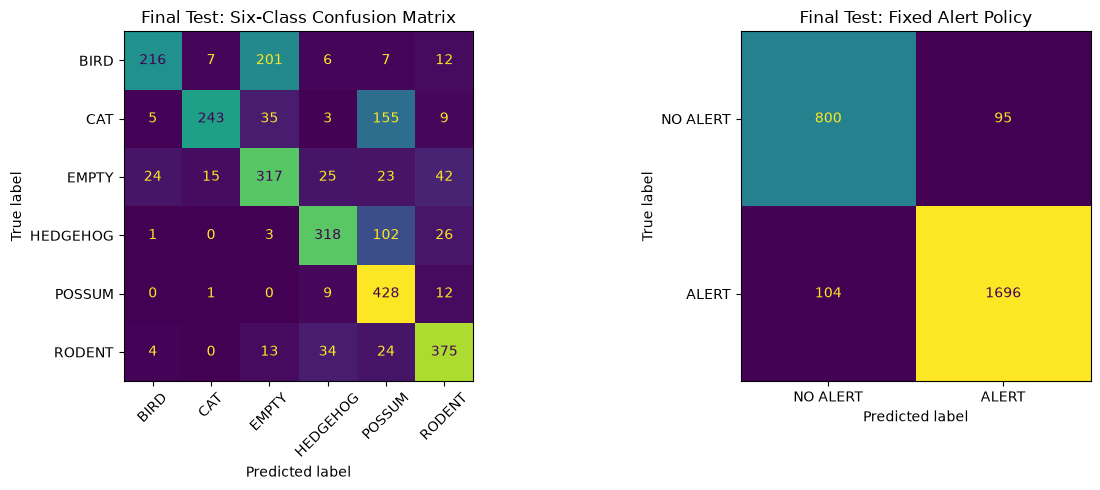

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    y_test_class_pred,
    labels=np.arange(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES,
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Final Test: Six-Class Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test_alert,
    y_test_alert_pred,
    labels=[0, 1],
    display_labels=["NO ALERT", "ALERT"],
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Final Test: Fixed Alert Policy")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## Discover
Most six-class errors happen inside the same group: birds are often predicted as empty, and cats and hedgehogs are often predicted as possums. These errors do not change the alert decision.  
 The errors that matter are the 95 false alerts, mostly empty frames predicted as animals, and the 104 missed alerts, mostly cats and rodents predicted as birds or empty.

# 7. Error Analysis and Explainability

## 7.1 Inspect False and Missed Alerts

False alerts: 95
Missed alerts: 104


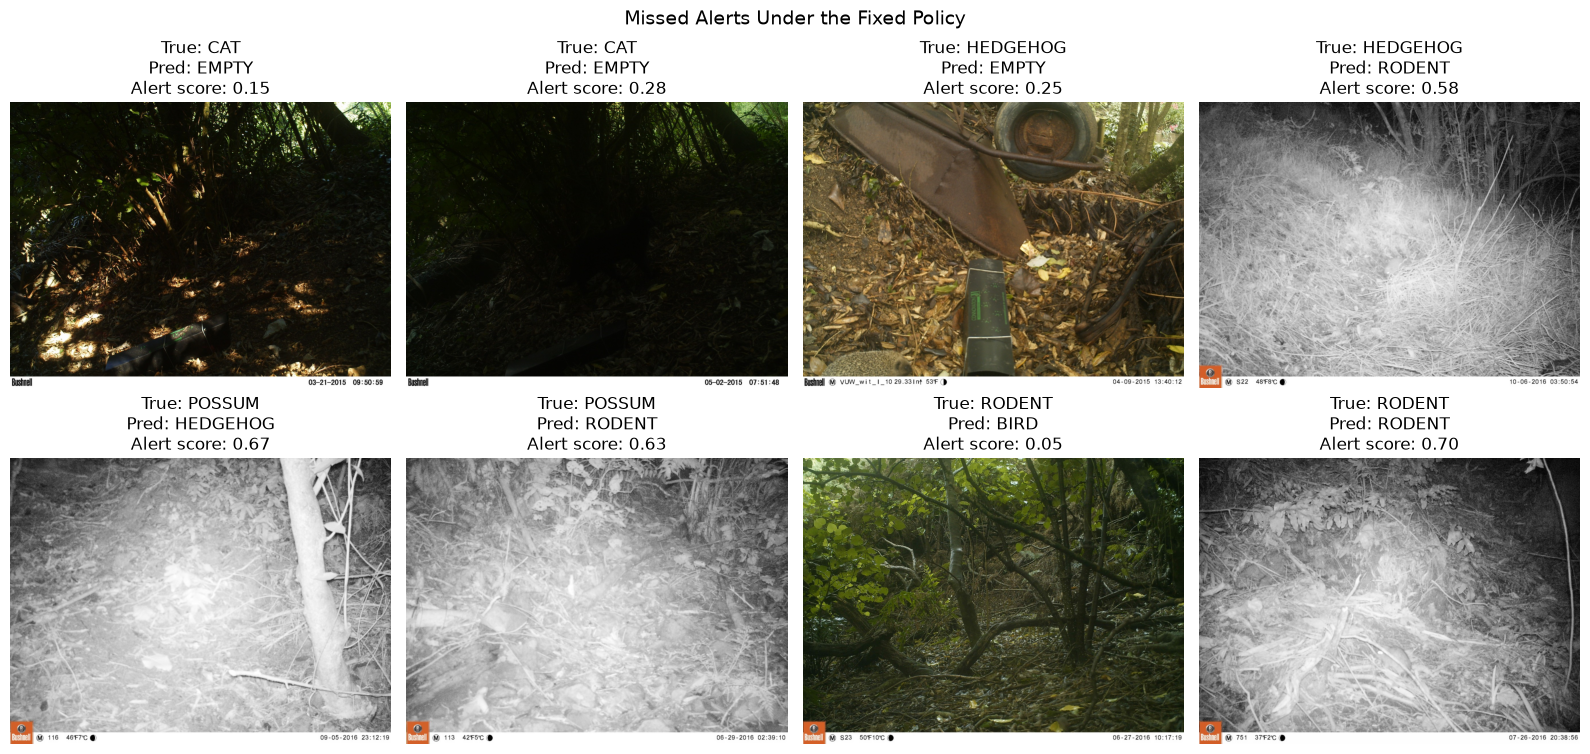

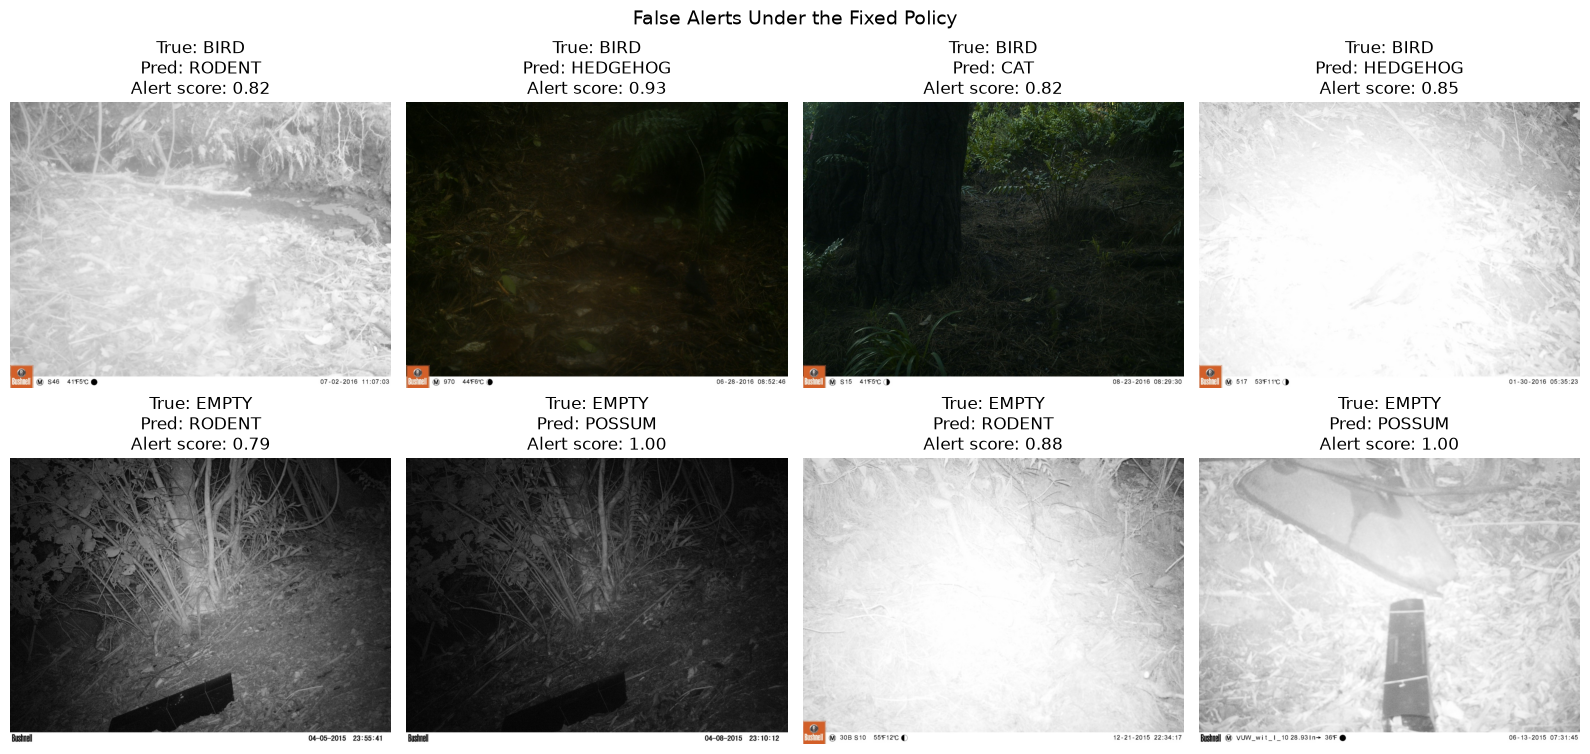

In [18]:
def show_alert_errors(predictions_df, mask, title, filename, per_class=2):
    """Plot error examples sampled at random from EACH true class
    (fixed seed, so the figure is repeatable), then save the figure. """
    subset = predictions_df.loc[mask]
    if subset.empty:
        print(f"No examples found for: {title}")
        return

    # Stratified sampling: up to `per_class` random examples per true class 
    parts = [
        group.sample(n=min(per_class, len(group)), random_state=10)
        for _, group in subset.groupby("true_class")
    ]
    examples = pd.concat(parts)
 
    columns = 4
    rows = int(np.ceil(len(examples) / columns))
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 4 * rows),
        squeeze=False,
    )

    for axis in axes.ravel():
        axis.axis("off")

    for axis, (_, row) in zip(axes.ravel(), examples.iterrows()):
        image_path = (
            CACHE_DATA_DIR
            / row["split"]
            / row["project_class"]
            / row["file"]
        )
        with Image.open(image_path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['predicted_class']}\n"
            f"Alert score: {row['selected_alert_score']:.2f}"
        )
        axis.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / filename,
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()


# False alert: no predator in the image, but the system raised an alert. 
false_alert_mask = (
    (test_predictions_df["true_alert"] == 0)
    & (test_predictions_df["predicted_alert"] == 1)
)
# Missed alert: a predator is present, but the system stayed silent. 
missed_alert_mask = (
    (test_predictions_df["true_alert"] == 1)
    & (test_predictions_df["predicted_alert"] == 0)
)

print("False alerts:", int(false_alert_mask.sum()))
print("Missed alerts:", int(missed_alert_mask.sum()))

# Missed alerts come from 4 true classes -> 2 each = 8 images. 
show_alert_errors(
    test_predictions_df,
    missed_alert_mask,
    "Missed Alerts Under the Fixed Policy",
    "final_missed_alerts.png",
    per_class=2,
)
# False alerts come from 2 true classes (BIRD, EMPTY) -> 4 each = 8 images 
show_alert_errors(
    test_predictions_df,
    false_alert_mask,
    "False Alerts Under the Fixed Policy",
    "final_false_alerts.png",
    per_class=4,
)

### Error Analysis: Missed and False Alerts

The examples below are for illustration only. They were chosen at random from each true class, using a fixed random seed, so they do not show every type of error.

**Missed alerts.** Four of the eight missed cases were predicted as BIRD or EMPTY, with low alert scores (0.05 to 0.28). The other four were predicted as an alert class, but their scores (0.58 to 0.70) were just below the 0.70 threshold. In most images, the animal is hard to see because the image is very dark, too bright from infrared light, or full of plants. In some images, we could not find the animal at all, so some errors may be caused by wrong labels or by animals that are too small.

**False alerts.** All false alerts have high scores (0.79 to 1.00), and two reach 1.00, so the model was very confident but wrong. Three of the four EMPTY images show a dark trap box on the ground, and the model may be reacting to this man-made object. Two images are almost completely white and show nothing clear. The BIRD images are dark or infrared, and the bird is small or hard to see.

In general, errors are related to dark or infrared images, small or hidden animals, objects in the background such as trap boxes, and images with very little information.

## 7.2 Grad-CAM

In [19]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handle = target_layer.register_forward_hook(
            self._forward_hook
        )

    def _forward_hook(self, module, inputs, output):
        self.activations = output.detach()
        output.register_hook(self._gradient_hook)

    def _gradient_hook(self, gradient):
        self.gradients = gradient.detach()

    def generate(self, input_tensor, target_class):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        logits[0, target_class].backward()

        activations = self.activations[0]
        gradients = self.gradients[0]
        weights = gradients.mean(dim=(1, 2), keepdim=True)
        cam = torch.relu((weights * activations).sum(dim=0))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(
            cam[None, None],
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        return cam.cpu().numpy()

    def close(self):
        self.handle.remove()


IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])


def prepare_gradcam_input(row):
    image_path = (
        CACHE_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )
    with Image.open(image_path) as image:
        tensor = eval_transform(image.convert("RGB"))

    display_image = tensor.permute(1, 2, 0).numpy()
    display_image = display_image * IMAGENET_STD + IMAGENET_MEAN
    display_image = np.clip(display_image, 0, 1)
    return tensor.unsqueeze(0).to(device), display_image


## 7.3 Grad-CAM Alert Examples

Use fixed examples for reproducibility. The missed-alert example was chosen
from visibly confirmed animal images for qualitative explanation only; this
choice does not alter the test predictions, counts, or reported metrics.


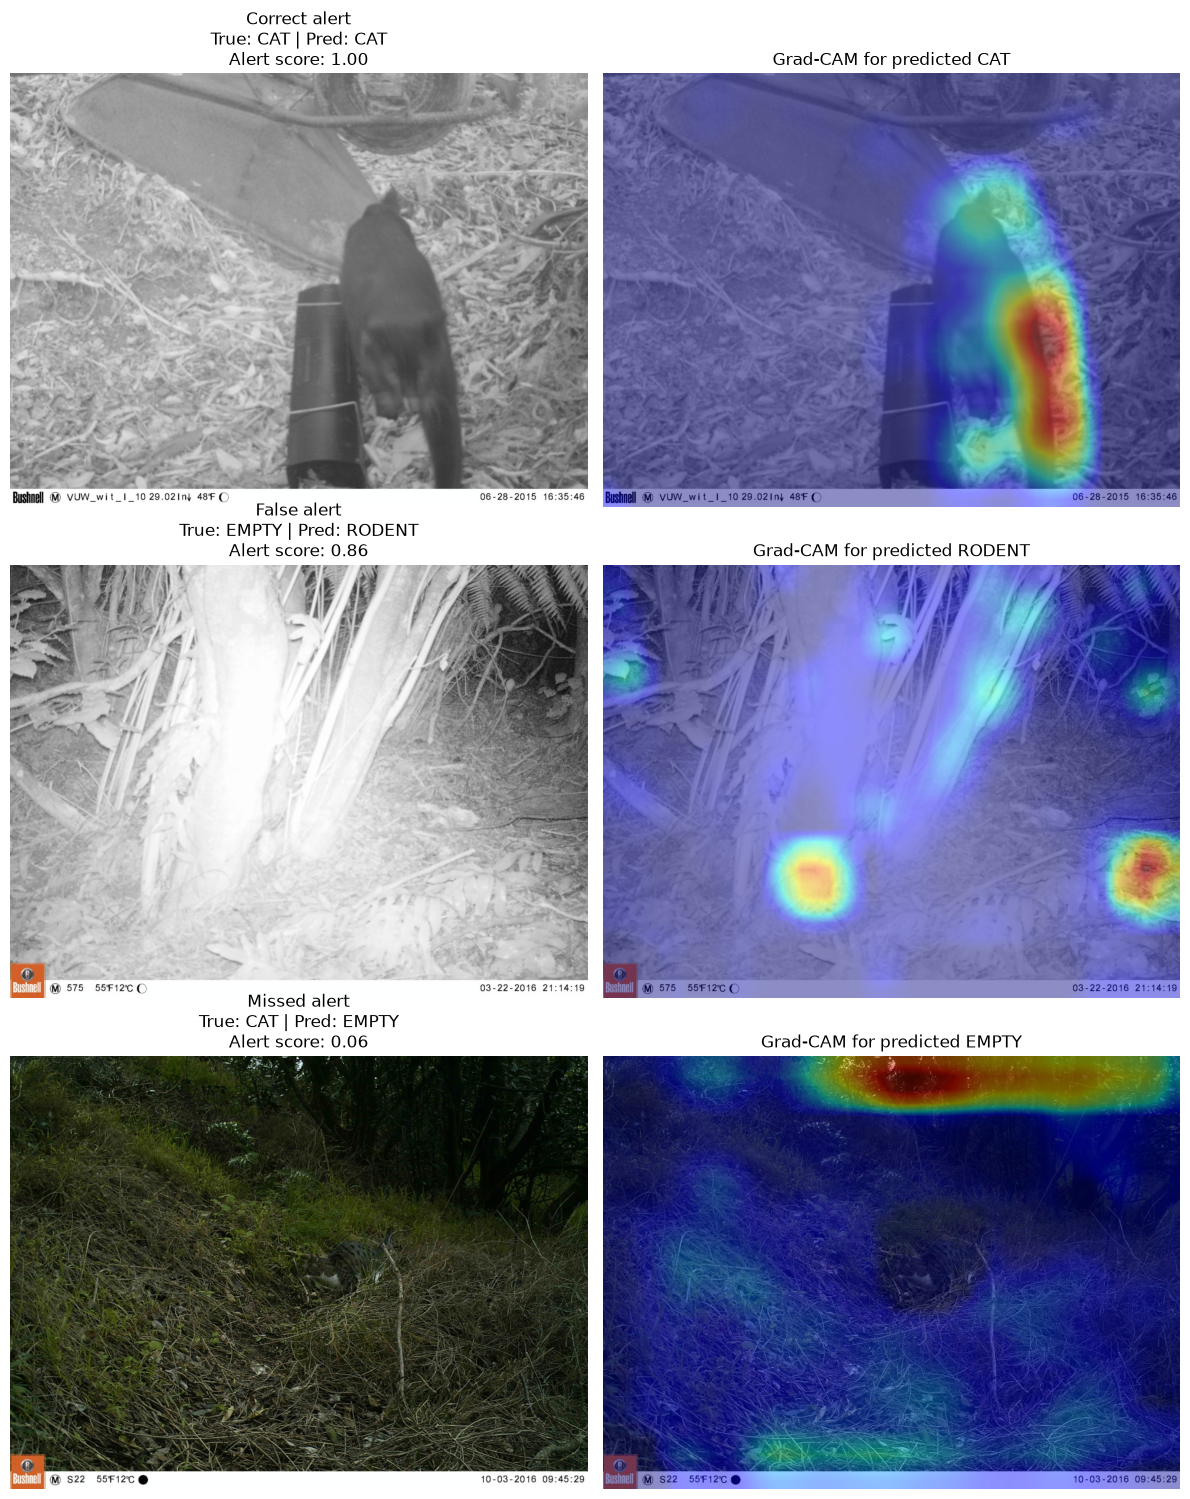

In [20]:
gradcam_cases = {
    "Correct alert": (
        (test_predictions_df["true_alert"] == 1)
        & (test_predictions_df["predicted_alert"] == 1)
    ),
    "False alert": false_alert_mask,
    "Missed alert": missed_alert_mask,
}

# Keep deterministic examples. For the missed-alert panel, use a
# manually verified image in which the cat is clearly visible. This is only
# qualitative case selection and does not change any evaluation metric.
preferred_example_files = {
    "Correct alert": "2806151635460359L101.jpg",
    "Missed alert": "031016094528022as221.jpg",
}

selected_gradcam_examples = []
for case_name, mask in gradcam_cases.items():
    candidates = test_predictions_df.loc[mask]
    if candidates.empty:
        continue

    preferred_file = preferred_example_files.get(case_name)
    if preferred_file is None:
        selected_row = candidates.sample(
            n=1,
            random_state=42,
        ).iloc[0]
    else:
        preferred_rows = candidates.loc[
            candidates["file"] == preferred_file
        ]
        if preferred_rows.empty:
            raise ValueError(
                f"Preferred {case_name} example was not found: "
                f"{preferred_file}"
            )
        selected_row = preferred_rows.iloc[0]

    selected_gradcam_examples.append((case_name, selected_row))

if not selected_gradcam_examples:
    raise ValueError("No Grad-CAM examples are available.")

gradcam = GradCAM(
    model=resnet_model,
    target_layer=resnet_model.layer4[-1],
)

fig, axes = plt.subplots(
    len(selected_gradcam_examples),
    2,
    figsize=(12, 5 * len(selected_gradcam_examples)),
    squeeze=False,
)

for row_number, (case_name, row) in enumerate(selected_gradcam_examples):
    input_tensor, display_image = prepare_gradcam_input(row)
    predicted_index = int(row["predicted_class_index"])
    heatmap = gradcam.generate(input_tensor, predicted_index)

    axes[row_number, 0].imshow(display_image)
    axes[row_number, 0].set_title(
        f"{case_name}\n"
        f"True: {row['true_class']} | Pred: {row['predicted_class']}\n"
        f"Alert score: {row['selected_alert_score']:.2f}"
    )
    axes[row_number, 0].axis("off")

    axes[row_number, 1].imshow(display_image)
    axes[row_number, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[row_number, 1].set_title(
        f"Grad-CAM for predicted {row['predicted_class']}"
    )
    axes[row_number, 1].axis("off")

gradcam.close()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "gradcam_alert_examples.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


### Grad-CAM Analysis

Grad-CAM was used to see which parts of an image influenced the model's prediction. **Red and yellow areas show stronger influence.** Three cases were examined. The correct alert and the missed alert were selected by hand, and the false alert was sampled at random with a fixed seed. They are used only to explain possible reasons for errors, not to measure performance.

**In the correct alert example**, the image was classified as CAT with an alert score of 1.00. The activation mainly covers the cat's body and tail, so in this case the model used relevant animal features.

**In the false alert example**, an EMPTY image was classified as RODENT. The activation is on bright vegetation and background objects, not on an animal. This suggests that background patterns can be mistaken for animal features.

**In the missed alert example**, the cat is visible near the centre-right of the image, but the model predicted EMPTY with an alert score of only 0.06. The activation is mainly on the brighter vegetation near the top and does not strongly cover the cat. The cat is small compared with the whole scene and has similar colours and textures to the background. This example is not typical: in the randomly sampled missed alerts (Section 7.1), the animal was usually hard to see.

In these examples, the model works well when the animal is large and clear, **but it may rely on background features and miss small animals in complex scenes.** More difficult training examples, more variation in lighting and animal position, and object-location annotations could make the model more reliable.

## 7.4 Infrared and Night-Time Analysis

In [7]:
# ## 7.4 Subgroup audit: image mode (infrared) and capture time 

# Mean |R-G| + |G-B| below this value = greyscale image (infrared). 
GREY_THRESHOLD = 3.0


def chroma(path):
    """Colourfulness of an image; low means greyscale (infrared). """
    with Image.open(path) as im:
        im.draft("RGB", (200, 150))   # fast low-resolution JPEG decoding  
        a = np.asarray(
            im.convert("RGB").resize((160, 120)), dtype=np.int16
        )[:110]                        # drop the info bar at the bottom 
    return np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()


def alert_rates(df, group):
    """Alert recall and false-alert rate per subgroup. """
    alert = df[df["true_alert"] == 1]        # predator images  
    no_alert = df[df["true_alert"] == 0]     # BIRD / EMPTY images  
    return pd.DataFrame({
        # mean of a 0/1 column = share of images predicted as alert 
        "alert_recall": alert.groupby(group)["predicted_alert"].mean(),
        "n_alert": alert.groupby(group).size(),
        "false_alert_rate": no_alert.groupby(group)["predicted_alert"].mean(),
        "n_no_alert": no_alert.groupby(group).size(),
    }).round(4)


audit_df = test_predictions_df.copy()

# Greyscale (infrared) flag for every test image 
audit_df["infrared"] = [
    chroma(CACHE_DATA_DIR / r.split / r.project_class / r.file) < GREY_THRESHOLD
    for r in audit_df.itertuples()
]

# Night = 19:00-05:59. Rows with an unreadable date count as "day". 
hour = pd.to_datetime(audit_df["date"], format="mixed", errors="coerce").dt.hour
audit_df["night"] = hour.isin(list(range(0, 6)) + list(range(19, 24)))

by_mode = alert_rates(audit_df, "infrared")
by_time = alert_rates(audit_df, "night")
print("By image mode (infrared = greyscale):\n", by_mode, "\n")
print("By capture time (night = 19:00-05:59):\n", by_time, "\n")

# Share of greyscale frames per class in a training sample (300 per class) 
train_sample = (
    pd.read_csv(METADATA_PATH)
    .query("split == 'train'")
    .groupby("project_class")
    .sample(300, random_state=0)
)
train_sample["infrared"] = [
    chroma(CACHE_DATA_DIR / r.split / r.project_class / r.file) < GREY_THRESHOLD
    for r in train_sample.itertuples()
]
train_share = (train_sample.groupby("project_class")["infrared"].mean() * 100).round(1)
print("Share of greyscale frames in the training sample (%):\n", train_share, "\n")

# Per-site accuracy (sites with at least 30 test images) 
site_acc = (
    audit_df.assign(correct=audit_df["predicted_class"] == audit_df["true_class"])
    .groupby("site")
    .agg(n=("file", "size"), accuracy=("correct", "mean"))
)
print("Per-site accuracy:\n", site_acc[site_acc["n"] >= 30]["accuracy"].describe().round(3))

by_mode.to_csv(RESULTS_DIR / "audit_by_image_mode.csv")
by_time.to_csv(RESULTS_DIR / "audit_by_capture_time.csv")
train_share.to_csv(RESULTS_DIR / "audit_train_greyscale_share.csv")

By image mode (infrared = greyscale):
           alert_recall  n_alert  false_alert_rate  n_no_alert
infrared                                                     
False           0.6063      127            0.0244         532
True            0.9677     1673            0.2259         363 

By capture time (night = 19:00-05:59):
        alert_recall  n_alert  false_alert_rate  n_no_alert
night                                                     
False        0.8227      361            0.0491         795
True         0.9722     1439            0.5600         100 

Share of greyscale frames in the training sample (%):
 project_class
BIRD         36.3
CAT          69.7
EMPTY        45.0
HEDGEHOG     99.7
POSSUM      100.0
RODENT       96.3
Name: infrared, dtype: float64 

Per-site accuracy:
 count    20.000
mean      0.723
std       0.141
min       0.373
25%       0.674
50%       0.768
75%       0.814
max       0.885
Name: accuracy, dtype: float64


**Lighting bias.** We checked the alert results by image type and time of day.   
Recall was 0.97 on greyscale (infrared) images but only 0.61 on colour images, and the false alert rate was 0.23 on infrared images but only 0.02 on colour images.   
At night, 56 of the 100 non-predator images (BIRD or EMPTY) caused an alert, compared with about 5% in the daytime.   
In the training sample, almost all HEDGEHOG (99.7%), POSSUM (100%) and RODENT (96.3%) images are greyscale, while only 36% of BIRD and 45% of EMPTY images are.   
  
This suggests that the model partly uses lighting as a cue for "predator", and not only the animal itself. This is a correlation, because predators in this dataset are mostly recorded at night. Some groups are also small (127 colour predator images and 100 night-time non-predator images), so these numbers should be read with care.  
  
To reduce this shortcut, future work could add random greyscale augmentation during training, and collect more colour images of predators and more night-time images of birds and empty frames.

# 8. Final Results and Discussion

After data cleaning, the final V2 dataset contained 17,963 images. Only extremely dark images with almost no useful visual information were excluded. Infrared or overexposed images were retained when the animal shape was still visible.

The pretrained ResNet18 achieved its best validation accuracy of 0.7107 at epoch 5, compared with approximately 0.4091 for the baseline CNN. On the final test set, ResNet18 achieved a six-class accuracy of 0.7039. This shows that transfer learning provided a large improvement over the simple baseline model.

The alert policy was selected using validation data only. The selected policy used the sum of the CAT, HEDGEHOG, POSSUM, and RODENT probabilities with a threshold of 0.70.When this fixed policy was applied to the test set, **it achieved an accuracy of 0.9262, precision of 0.9470, recall of 0.9422, and F1-score of 0.9446.** There were 95 false alerts and 104 missed alerts among 2,695 test images.

The six-class results show that POSSUM and RODENT were recognised more reliably, while BIRD and CAT had lower recall. Common errors included BIRD being predicted as EMPTY, CAT being predicted as POSSUM, and HEDGEHOG being predicted as POSSUM. However, many of these class errors did not change the final alert decision because the alert system combines the four alert-animal probabilities.

The error examples and Grad-CAM results show that the model can focus on the animal when it is large and clear. However, it may also respond to vegetation, bright infrared regions, and other background patterns. Small or partly hidden animals can therefore be missed even when they are visible to a human.

Overall, the V2 system provides strong binary alert performance but only moderate six-class classification performance. **Future work could include more difficult training examples, sequence-aware predictions, hard-negative mining, and object detection or bounding-box annotations to help the model focus more directly on animals.**